### Pillow 4: Pixel - Übungen

Wie funktionieren die Werkzeuge eines Bildbearbeitungsprogramms? In diesem Notebook programmierst du sie selbst: Negativ, Graustufen, Schwarz-Weiß, Sepia,
Verpixeln, Weichzeichnen und Kanten finden. Zuerst mit Schleifen über alle Pixel, dann viel schneller mit numpy, das ein Bild als Array behandelt.
Zum Schluss versteckst du eine geheime Nachricht in einem Foto.

Die Reihe hat vier Notebooks:

1. Grundlagen: Bilder erzeugen, Pixel, Farben, Speichern und Öffnen
2. Zeichnen: Formen, Text, Grafiken mit Schleifen und Funktionen
3. Bearbeiten: Ausschneiden, Drehen, Filter, Helligkeit, Collagen, animierte GIFs
4. **Pixel**: Bildverarbeitung selbst programmieren, mit Schleifen und mit numpy (dieses Notebook)

Vorausgesetzt werden *Pillow: Grundlagen* und *numpy: Grundlagen*; *numpy: Zweidimensionale Arrays* ist hilfreich.

**Bilder anzeigen:** Steht ein Bild in der **letzten Zeile** einer Zelle, zeigt JupyterLab es an. Mehrere Bilder in einer Zelle zeigt man mit `display(bild)` an.
Die erwarteten Ausgaben zeigen die Bilder höchstens 320 Pixel groß; große Bilder (Fotos) sind dort verkleinert.

**Fotos:** Neben den Notebooks liegen zwei Fotos mit je 640 × 427 Pixeln: `pagode.png` (ein chinesischer Tempel) und `bluete.png` (eine Blüte).
Fotos: Daniel Buechele, [CC BY 2.0](https://creativecommons.org/licenses/by/2.0/), aus dem Paket scikit-learn.
Eigene Fotos kannst du mit dem Pfeil-Symbol über der Dateiliste links hochladen und dann mit `Image.open('dateiname.jpg')` öffnen.

Jeder Abschnitt beginnt mit kurzen Erklärungen und Beispielen. Führe die Beispiele aus und probiere sie ruhig ein wenig aus.
Danach folgen viele kleine Übungen. Wenn etwas vorgegeben ist, steht es schon in der Codezelle.

Unter den Aufgaben kannst du jeweils die Lösung aufklappen. Versuche es aber immer zuerst selbst!
Bei den Aufgaben „Was wird ausgegeben?“ überlegst du zuerst, führst dann die Zelle aus und vergleichst.
Die aufklappbare Lösung erklärt dort, wie die Ausgabe zustande kommt.

#### Bildanzeige einrichten

**Führe diese Zelle zuerst aus** (nach jedem Neustart des Kernels wieder). Im Browser-Python von JupyterLite zeigt `display(bild)` sonst nur ein leeres Bild an;
die Zelle sorgt dafür, dass Pillow-Bilder dort richtig übertragen werden. Wie sie funktioniert, musst du nicht verstehen.

In [ ]:
import base64
import io
from IPython import get_ipython
from PIL import Image

def als_png(bild):
    puffer = io.BytesIO()
    bild.save(puffer, 'PNG')
    return base64.b64encode(puffer.getvalue()).decode('ascii')

def kein_jpeg(bild):
    return None

ipython = get_ipython()
if ipython is not None:
    ipython.display_formatter.formatters['image/png'].for_type(Image.Image, als_png)
    ipython.display_formatter.formatters['image/jpeg'].for_type(Image.Image, kein_jpeg)
print('Bereit: Bilder werden auch mit display() angezeigt.')

## 1. Effekte mit Pixelschleifen

#### Jedes Pixel umrechnen

Viele Effekte rechnen **jedes Pixel für sich** um. Das **Negativ** ersetzt jeden Farbanteil `w` durch `255 - w`. Die Schleife läuft über alle `x` und `y`,
liest die Farbe, rechnet und schreibt das Ergebnis in ein neues Bild.

`pixel = bild.load()` liefert ein Objekt, mit dem man über `pixel[x, y]` schneller lesen und schreiben kann als mit `getpixel()`/`putpixel()`.
Das Foto wird vorher verkleinert, weil Schleifen über alle 273 000 Pixel im Browser einige Sekunden dauern.

In [ ]:
from PIL import Image

foto = Image.open('bluete.png').resize((213, 142))

ergebnis = Image.new('RGB', foto.size)
alt = foto.load()
neu = ergebnis.load()
for x in range(foto.width):
    for y in range(foto.height):
        r, g, b = alt[x, y]
        neu[x, y] = (255 - r, 255 - g, 255 - b)
print(alt[100, 70], neu[100, 70])
ergebnis

#### Aufgabe 1.1

Erzeuge ein Graustufenbild der Blüte, in dem jedes Pixel den **Mittelwert** `(r + g + b) // 3` als Grauwert bekommt (Modus `L`). Gib den Grauwert von (100 | 70) aus.

**Erwartete Ausgabe:**

```
121
```

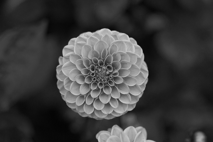

In [ ]:
from PIL import Image

foto = Image.open('bluete.png').resize((213, 142))
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image

foto = Image.open('bluete.png').resize((213, 142))
grau = Image.new('L', foto.size)
alt = foto.load()
neu = grau.load()
for x in range(foto.width):
    for y in range(foto.height):
        r, g, b = alt[x, y]
        neu[x, y] = (r + g + b) // 3
print(neu[100, 70])
grau
```

</details>

#### Aufgabe 1.2

Vergleiche den Mittelwert mit der Formel von Pillow `0.299 r + 0.587 g + 0.114 b` (gerundet) und mit `foto.convert('L')` für die Pixel (100 | 70), (20 | 20) und (200 | 130).

**Erwartete Ausgabe:**

```
(100, 70) 121 127 127
(20, 20) 37 38 38
(200, 130) 32 40 40
```

In [ ]:
from PIL import Image

foto = Image.open('bluete.png').resize((213, 142))
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image

foto = Image.open('bluete.png').resize((213, 142))
alt = foto.load()
grau = foto.convert('L')
for position in [(100, 70), (20, 20), (200, 130)]:
    r, g, b = alt[position]
    print(position, (r + g + b) // 3, round(0.299 * r + 0.587 * g + 0.114 * b), grau.getpixel(position))
```

</details>

#### Aufgabe 1.3

**Schwarz-Weiß mit Schwellenwert**: Jedes Pixel, dessen Grauwert (aus `convert('L')`) größer als 100 ist, wird weiß, alle anderen schwarz. Zähle die weißen Pixel.

**Erwartete Ausgabe:**

```
6541
```

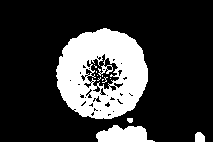

In [ ]:
from PIL import Image

foto = Image.open('bluete.png').resize((213, 142))
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image

foto = Image.open('bluete.png').resize((213, 142))
grau = foto.convert('L')
sw = Image.new('L', foto.size)
alt = grau.load()
neu = sw.load()
weiss = 0
for x in range(foto.width):
    for y in range(foto.height):
        if alt[x, y] > 100:
            neu[x, y] = 255
            weiss += 1
        else:
            neu[x, y] = 0
print(weiss)
sw
```

</details>

#### Aufgabe 1.4

**Sepia** (wie ein altes Foto): Die neuen Anteile sind `0.393 r + 0.769 g + 0.189 b`, `0.349 r + 0.686 g + 0.168 b` und `0.272 r + 0.534 g + 0.131 b`, jeweils mit `int()`
abgeschnitten und höchstens 255 (`min(255, ...)`). Wende Sepia auf die Pagode an und gib die neue Farbe von (100 | 70) aus.

**Erwartete Ausgabe:**

```
(142, 126, 98)
```

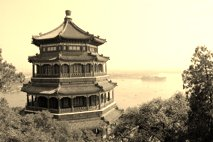

In [ ]:
from PIL import Image

foto = Image.open('pagode.png').resize((213, 142))
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image

foto = Image.open('pagode.png').resize((213, 142))
ergebnis = Image.new('RGB', foto.size)
alt = foto.load()
neu = ergebnis.load()
for x in range(foto.width):
    for y in range(foto.height):
        r, g, b = alt[x, y]
        neu[x, y] = (min(255, int(0.393 * r + 0.769 * g + 0.189 * b)),
                     min(255, int(0.349 * r + 0.686 * g + 0.168 * b)),
                     min(255, int(0.272 * r + 0.534 * g + 0.131 * b)))
print(neu[100, 70])
ergebnis
```

</details>

#### Aufgabe 1.5

Spiegle die Pagode **selbst** (ohne `ImageOps`): Das Pixel (x | y) kommt an die Stelle (breite − 1 − x | y). Prüfe mit `ImageOps.mirror()`, dass beide gleich sind
(`np.array_equal(np.array(a), np.array(b))`).

**Erwartete Ausgabe:**

```
True
```

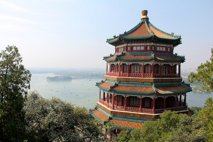

In [ ]:
from PIL import Image

foto = Image.open('pagode.png').resize((213, 142))
from PIL import ImageOps
import numpy as np
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image

foto = Image.open('pagode.png').resize((213, 142))
from PIL import ImageOps
import numpy as np
gespiegelt = Image.new('RGB', foto.size)
alt = foto.load()
neu = gespiegelt.load()
for x in range(foto.width):
    for y in range(foto.height):
        neu[foto.width - 1 - x, y] = alt[x, y]
print(np.array_equal(np.array(gespiegelt), np.array(ImageOps.mirror(foto))))
gespiegelt
```

</details>

#### Aufgabe 1.6

**Farbe hervorheben**: Mache alle Pixel der Blüte grau (Mittelwert), bei denen Rot nicht deutlich überwiegt (`r < g + b`). Die anderen bleiben farbig.

**Erwartete Ausgabe:**



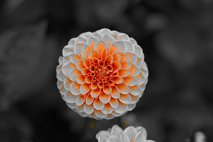

In [ ]:
from PIL import Image

foto = Image.open('bluete.png').resize((213, 142))
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image

foto = Image.open('bluete.png').resize((213, 142))
ergebnis = foto.copy()
pixel = ergebnis.load()
for x in range(foto.width):
    for y in range(foto.height):
        r, g, b = pixel[x, y]
        if r < g + b:
            m = (r + g + b) // 3
            pixel[x, y] = (m, m, m)
ergebnis
```

</details>

#### Aufgabe 1.7

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
r, g, b = 200, 100, 50
print(255 - r, 255 - g, 255 - b)
print((r + g + b) // 3)
print(min(255, int(0.393 * r + 0.769 * g + 0.189 * b)))

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

**Ausgabe:**

```
55 155 205
116
164
```

- Negativ: `(55, 155, 205)`, ausgegeben als `55 155 205`.
- Mittelwert: `350 // 3 = 116`.
- Sepia-Rot: `78.6 + 76.9 + 9.45 = 164.95`, abgeschnitten `164` (kleiner als 255).

</details>

## 2. Bilder als numpy-Arrays

#### `np.array(bild)` und `Image.fromarray()`

`np.array(foto)` macht aus einem Bild ein Array der Form `(hoehe, breite, 3)`: Achtung, **zuerst die Zeile `y`**, dann die Spalte `x`, dann der Farbkanal.
`a[y, x]` ist also das Pixel (x | y), `a[:, :, 0]` der Rot-Kanal. Die Werte haben den Typ `uint8` (ganze Zahlen 0 bis 255).
`Image.fromarray(array)` macht daraus wieder ein Bild; das Array muss dafür den Typ `uint8` haben.

Rechnungen wirken auf alle Pixel gleichzeitig und sind deshalb viel schneller als Schleifen.

In [ ]:
import numpy as np
from PIL import Image

foto = Image.open('bluete.png')
a = np.array(foto)

print(a.shape)
print(a[70, 100], foto.getpixel((100, 70)))
negativ = 255 - a
Image.fromarray(negativ)

#### Vorsicht: Überlauf bei `uint8`

`uint8` kann nur Zahlen von 0 bis 255 speichern. Rechnungen, deren Ergebnis darüber oder darunter liegt, „laufen über“: `250 + 10` ergibt 4. Deshalb rechnet man mit
`a.astype(int)` (oder `float`), begrenzt das Ergebnis mit `np.clip(werte, 0, 255)` und wandelt danach mit `.astype(np.uint8)` zurück.

In [ ]:
import numpy as np

a = np.array([250, 100, 5], dtype=np.uint8)
print(a + 10)
print(np.clip(a.astype(int) + 10, 0, 255).astype(np.uint8))

#### Aufgabe 2.1

Gib die Form des Pagoden-Arrays, die Farbe des Pixels (x = 320 | y = 200) und den größten Wert im Blau-Kanal aus.

**Erwartete Ausgabe:**

```
(427, 640, 3)
[237 226 222]
255
```

In [ ]:
import numpy as np
from PIL import Image

foto = Image.open('pagode.png')
a = np.array(foto)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from PIL import Image

foto = Image.open('pagode.png')
a = np.array(foto)
print(a.shape)
print(a[200, 320])
print(a[:, :, 2].max())
```

</details>

#### Aufgabe 2.2

Erzeuge Graustufen mit numpy: den Mittelwert über die drei Kanäle (`a.mean(axis=2)`), umgewandelt in `uint8`. Gib die Form des Ergebnisses aus und zeige es an.

**Erwartete Ausgabe:**

```
(427, 640)
```

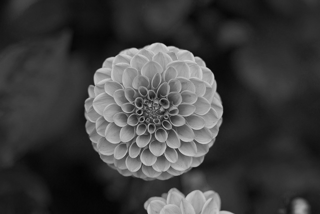

In [ ]:
import numpy as np
from PIL import Image

foto = Image.open('bluete.png')
a = np.array(foto)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from PIL import Image

foto = Image.open('bluete.png')
a = np.array(foto)
grau = a.mean(axis=2).astype(np.uint8)
print(grau.shape)
Image.fromarray(grau)
```

</details>

#### Aufgabe 2.3

Schwarz-Weiß mit numpy: Wandle die Blüte mit `convert('L')` in ein Array um, setze alle Werte über 100 auf 255 und den Rest auf 0 (`np.where`), zähle die weißen Pixel und zeige
das Bild an.

**Erwartete Ausgabe:**

```
58248
```

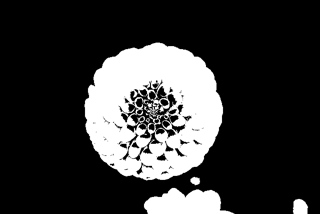

In [ ]:
import numpy as np
from PIL import Image

grau = np.array(Image.open('bluete.png').convert('L'))
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from PIL import Image

grau = np.array(Image.open('bluete.png').convert('L'))
sw = np.where(grau > 100, 255, 0).astype(np.uint8)
print((sw == 255).sum())
Image.fromarray(sw)
```

</details>

#### Aufgabe 2.4

Mache die Pagode heller, indem du zu jedem Wert 60 addierst, einmal falsch direkt mit `uint8` (Überlauf) und einmal richtig mit `astype(int)` und `np.clip`. Zeige beide an.

**Erwartete Ausgabe:**



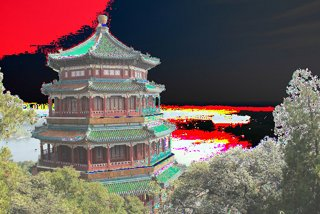

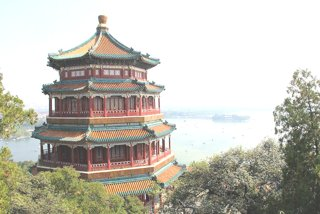

In [ ]:
import numpy as np
from PIL import Image

foto = Image.open('pagode.png')
a = np.array(foto)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from PIL import Image

foto = Image.open('pagode.png')
a = np.array(foto)
display(Image.fromarray(a + 60))
Image.fromarray(np.clip(a.astype(int) + 60, 0, 255).astype(np.uint8))
```

</details>

#### Aufgabe 2.5

Spiegeln, drehen und ausschneiden nur mit Slicing: `a[:, ::-1]` (links/rechts), `a[::-1]` (oben/unten), `a[100:300, 200:440]` (Zeilen 100 bis 299, Spalten 200 bis 439).
Gib die Formen aus und zeige die drei Bilder an.

**Erwartete Ausgabe:**

```
(427, 640, 3)
(427, 640, 3)
(200, 240, 3)
```

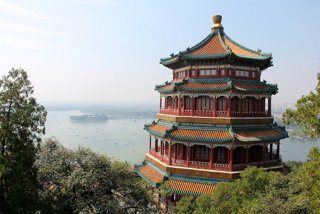

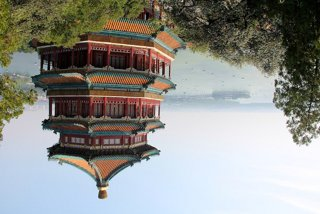

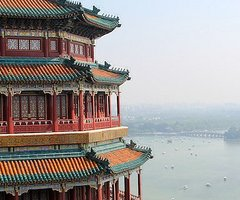

In [ ]:
import numpy as np
from PIL import Image

foto = Image.open('pagode.png')
a = np.array(foto)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from PIL import Image

foto = Image.open('pagode.png')
a = np.array(foto)
for teil in [a[:, ::-1], a[::-1], a[100:300, 200:440]]:
    print(teil.shape)
    display(Image.fromarray(teil))
```

</details>

#### Aufgabe 2.6

Sepia mit numpy: Die drei neuen Kanäle sind die Formeln aus Abschnitt 1 (mit den Kanälen `r = a[:, :, 0]` usw. als Kommazahlen). Setze sie mit `np.stack([...], axis=2)` zusammen,
begrenze mit `np.clip` auf 255 und zeige das Bild an. Gib die neue Farbe des Pixels (x = 320 | y = 200) aus.

**Erwartete Ausgabe:**

```
[255 255 214]
```

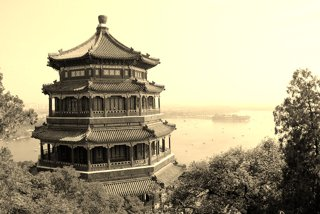

In [ ]:
import numpy as np
from PIL import Image

foto = Image.open('pagode.png')
a = np.array(foto)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from PIL import Image

foto = Image.open('pagode.png')
a = np.array(foto)
r = a[:, :, 0].astype(float)
g = a[:, :, 1].astype(float)
b = a[:, :, 2].astype(float)
sepia = np.stack([0.393 * r + 0.769 * g + 0.189 * b,
                  0.349 * r + 0.686 * g + 0.168 * b,
                  0.272 * r + 0.534 * g + 0.131 * b], axis=2)
sepia = np.clip(sepia, 0, 255).astype(np.uint8)
print(sepia[200, 320])
Image.fromarray(sepia)
```

</details>

#### Aufgabe 2.7

Vertausche die Farbkanäle der Blüte mit `a[:, :, [2, 0, 1]]` (Blau, Rot, Grün) und zeige das Ergebnis an.

**Erwartete Ausgabe:**



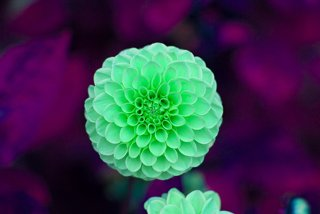

In [ ]:
import numpy as np
from PIL import Image

foto = Image.open('bluete.png')
a = np.array(foto)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from PIL import Image

foto = Image.open('bluete.png')
a = np.array(foto)
Image.fromarray(a[:, :, [2, 0, 1]])
```

</details>

#### Aufgabe 2.8

Erzeuge ein Bild direkt aus einem Array: `np.zeros((100, 256, 3), dtype=np.uint8)`, dessen Rot-Kanal in jeder Zeile die Werte 0 bis 255 hat (`np.arange(256)`) und dessen
Blau-Kanal 255 − Rot ist. Zeige es an.

**Erwartete Ausgabe:**



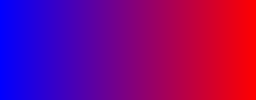

In [ ]:
import numpy as np
from PIL import Image
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from PIL import Image
a = np.zeros((100, 256, 3), dtype=np.uint8)
a[:, :, 0] = np.arange(256)
a[:, :, 2] = 255 - np.arange(256)
Image.fromarray(a)
```

</details>

#### Aufgabe 2.9

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
import numpy as np

a = np.zeros((4, 6, 3), dtype=np.uint8)
a[1, 5] = [255, 0, 0]
print(a.shape)
print(a[1, 5], a[0, 0])
print(np.array([200], dtype=np.uint8) + np.array([100], dtype=np.uint8))

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

**Ausgabe:**

```
(4, 6, 3)
[255   0   0] [0 0 0]
[44]
```

- 4 Zeilen, 6 Spalten, 3 Kanäle: `(4, 6, 3)`.
- `a[1, 5]` ist Zeile 1, Spalte 5, also das Pixel (5 | 1): `[255   0   0]`; `a[0, 0]` ist schwarz: `[0 0 0]`.
- `200 + 100 = 300` passt nicht in `uint8` und läuft über: `300 - 256 = 44`, also `[44]`.

</details>

## 3. Verpixeln

#### Blöcke mitteln

Beim **Verpixeln** (Mosaik) wird das Bild in Blöcke von z. B. 10 × 10 Pixeln geteilt, und jeder Block bekommt die mittlere Farbe seiner Pixel.
Mit Pillow geht das in zwei Schritten: stark verkleinern (jeder Block wird ein Pixel) und mit `NEAREST` wieder vergrößern.

In [ ]:
from PIL import Image

foto = Image.open('pagode.png')
klein = foto.resize((foto.width // 16, foto.height // 16))
mosaik = klein.resize(foto.size, Image.NEAREST)
print(klein.size)
mosaik

#### Aufgabe 3.1

Verpixle die Blüte mit Blöcken von 8, 20 und 40 Pixeln (zweimal `resize` wie im Beispiel) und zeige die drei Ergebnisse an.

**Erwartete Ausgabe:**



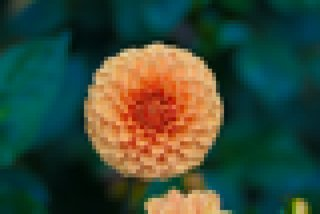

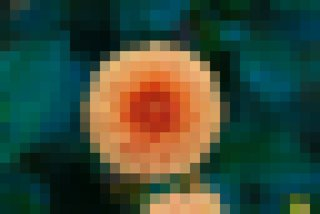

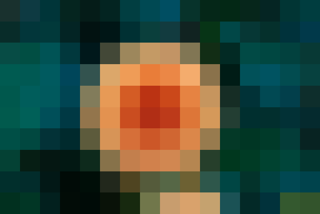

In [ ]:
from PIL import Image

foto = Image.open('bluete.png')
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image

foto = Image.open('bluete.png')
for block in [8, 20, 40]:
    klein = foto.resize((foto.width // block, foto.height // block))
    display(klein.resize(foto.size, Image.NEAREST))
```

</details>

#### Aufgabe 3.2

Verpixle mit numpy selbst: Schneide das Pagoden-Array auf ein Vielfaches von 20 zu (`a[:420, :640]`), gehe in einer Schleife über alle 20 × 20-Blöcke und setze jeden Block auf
seinen Mittelwert (`block.mean(axis=(0, 1))`). Gib die neue Farbe des Blocks oben links aus.

**Erwartete Ausgabe:**

```
[177 203 232]
```

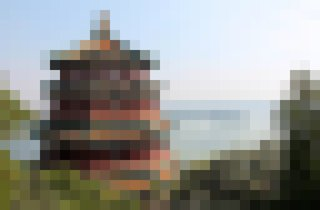

In [ ]:
import numpy as np
from PIL import Image

foto = Image.open('pagode.png')
a = np.array(foto)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from PIL import Image

foto = Image.open('pagode.png')
a = np.array(foto)
b = a[:420, :640].copy()
for y in range(0, 420, 20):
    for x in range(0, 640, 20):
        b[y:y + 20, x:x + 20] = b[y:y + 20, x:x + 20].mean(axis=(0, 1))
print(b[0, 0])
Image.fromarray(b)
```

</details>

#### Aufgabe 3.3

**Gesicht unkenntlich machen**: Verpixle nur den Bereich (200 | 50) bis (440 | 250) der Pagode (Blöcke von 12 Pixeln) und füge ihn wieder ein (`crop`, `resize`, `paste`).

**Erwartete Ausgabe:**



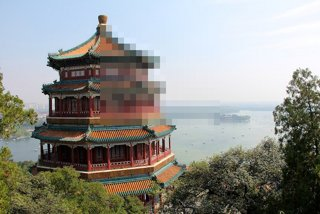

In [ ]:
from PIL import Image

foto = Image.open('pagode.png')
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image

foto = Image.open('pagode.png')
bereich = foto.crop((200, 50, 440, 250))
klein = bereich.resize((bereich.width // 12, bereich.height // 12))
ergebnis = foto.copy()
ergebnis.paste(klein.resize(bereich.size, Image.NEAREST), (200, 50))
ergebnis
```

</details>

## 4. Histogramme

#### Wie oft kommt jede Helligkeit vor?

`grau.histogram()` gibt für ein Graustufenbild eine Liste mit 256 Zahlen zurück: wie viele Pixel die Helligkeit 0, 1, ..., 255 haben. Bei einem RGB-Bild sind es
768 Zahlen (erst Rot, dann Grün, dann Blau). Ein dunkles Bild hat viele kleine Helligkeiten, ein kontrastarmes nur Werte in einem schmalen Bereich.
Gezeichnet wird das Histogramm z. B. mit `plt.bar(range(256), histogramm)`.

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

grau = Image.open('bluete.png').convert('L')
histogramm = grau.histogram()
print(len(histogramm), sum(histogramm))
print(histogramm.index(max(histogramm)))
plt.bar(range(256), histogramm, width=1)
plt.show()

#### Aufgabe 4.1

Gib für die Pagode in Graustufen aus: die häufigste Helligkeit, wie oft sie vorkommt, die Anzahl der Pixel mit Helligkeit unter 50 (`sum(histogramm[:50])`) und die
mittlere Helligkeit (eine Nachkommastelle, aus dem Histogramm: Summe von Helligkeit mal Anzahl geteilt durch die Pixelzahl).

**Erwartete Ausgabe:**

```
209 3784
53036
144.7
```

In [ ]:
from PIL import Image

grau = Image.open('pagode.png').convert('L')
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image

grau = Image.open('pagode.png').convert('L')
histogramm = grau.histogram()
haeufigste = histogramm.index(max(histogramm))
print(haeufigste, histogramm[haeufigste])
print(sum(histogramm[:50]))
summe = 0
for wert in range(256):
    summe += wert * histogramm[wert]
print(f'{summe / sum(histogramm):.1f}')
```

</details>

#### Aufgabe 4.2

Zeichne die Histogramme der drei Farbkanäle der Blüte als drei Linien (rot, grün, blau) in ein Diagramm. `foto.histogram()` liefert alle 768 Werte hintereinander.

**Erwartete Ausgabe:**



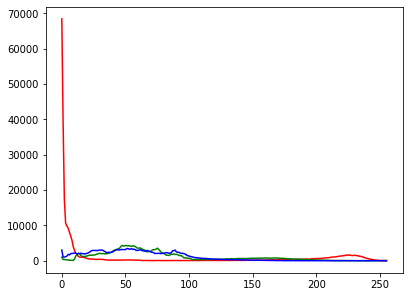

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

foto = Image.open('bluete.png')
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image
import matplotlib.pyplot as plt

foto = Image.open('bluete.png')
h = foto.histogram()
plt.plot(h[0:256], color='red')
plt.plot(h[256:512], color='green')
plt.plot(h[512:768], color='blue')
plt.show()
```

</details>

#### Aufgabe 4.3

`ImageOps.equalize()` verteilt die Helligkeiten gleichmäßiger und verstärkt so den Kontrast. Zeige die Pagode in Graustufen vorher und nachher an und zeichne beide Histogramme
übereinander (zwei `plt.plot()` mit Legende).

**Erwartete Ausgabe:**



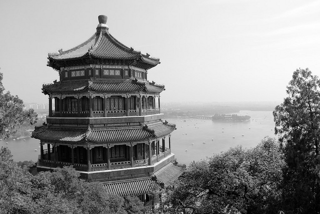

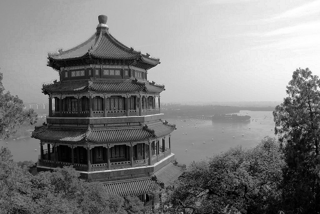

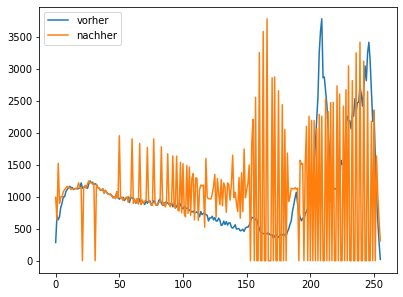

In [ ]:
from PIL import Image

grau = Image.open('pagode.png').convert('L')
from PIL import ImageOps
import matplotlib.pyplot as plt
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image

grau = Image.open('pagode.png').convert('L')
from PIL import ImageOps
import matplotlib.pyplot as plt
ausgeglichen = ImageOps.equalize(grau)
display(grau)
display(ausgeglichen)
plt.plot(grau.histogram(), label='vorher')
plt.plot(ausgeglichen.histogram(), label='nachher')
plt.legend()
plt.show()
```

</details>

#### Aufgabe 4.4

Zeichne das Histogramm der Pagode in Graustufen **selbst mit Pillow**: ein weißes Bild 256 × 100, für jede Helligkeit `w` eine senkrechte Linie bei `x = w`, deren Länge
der Anzahl entspricht (größte Anzahl = 100 Pixel).

**Erwartete Ausgabe:**



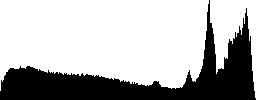

In [ ]:
from PIL import Image

grau = Image.open('pagode.png').convert('L')
from PIL import ImageDraw
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image

grau = Image.open('pagode.png').convert('L')
from PIL import ImageDraw
histogramm = grau.histogram()
groesste = max(histogramm)
bild = Image.new('RGB', (256, 100), 'white')
zeichner = ImageDraw.Draw(bild)
for w in range(256):
    laenge = histogramm[w] / groesste * 100
    zeichner.line((w, 99, w, 99 - laenge), fill='black')
bild
```

</details>

#### Aufgabe 4.5

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
from PIL import Image

bild = Image.new('L', (10, 5), 0)
for x in range(4):
    for y in range(5):
        bild.putpixel((x, y), 255)
h = bild.histogram()
print(len(h), h[0], h[255], sum(h[1:255]))

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

**Ausgabe:**

```
256 30 20 0
```

Das Bild hat 50 Pixel. Die ersten 4 Spalten (`4 · 5 = 20` Pixel) sind weiß, der Rest (30) schwarz.
Ausgabe: `256 30 20 0`; andere Helligkeiten kommen nicht vor.

</details>

## 5. Weichzeichnen und Kanten selbst berechnen

#### Nachbarn verrechnen

Ein **Weichzeichner** ersetzt jedes Pixel durch den Mittelwert aus ihm und seinen 8 Nachbarn (ein 3 × 3-Feld). Mit numpy-Slicing kann man die neun verschobenen Kopien des
Arrays addieren: `g[y + dy, x + dx]` für alle `dy`, `dx` von −1 bis 1. Am Rand fehlen Nachbarn; deshalb rechnet man nur das Innere aus (das Ergebnis ist 2 Pixel schmaler und niedriger).

**Kanten** sind Stellen, an denen sich die Helligkeit stark ändert. Die Differenz `g[:, 1:] - g[:, :-1]` zweier waagerecht benachbarter Pixel ist dort groß.

In [ ]:
import numpy as np
from PIL import Image

g = np.array(Image.open('pagode.png').convert('L')).astype(int)
h, b = g.shape
summe = np.zeros((h - 2, b - 2), dtype=int)
for dy in [-1, 0, 1]:
    for dx in [-1, 0, 1]:
        summe += g[1 + dy:h - 1 + dy, 1 + dx:b - 1 + dx]
weich = (summe // 9).astype(np.uint8)
print(weich.shape)
Image.fromarray(weich)

#### Aufgabe 5.1

Berechne den 3 × 3-Weichzeichner wie im Beispiel und vergleiche den Wert in Zeile 100, Spalte 300 des Originals mit dem Mittelwert seiner 9 Nachbarn
(`g[99:102, 299:302].mean()`, eine Nachkommastelle) und mit dem Ergebnis des Weichzeichners an derselben Stelle (dort `weich[99, 299]`, weil das Ergebnis um 1 verschoben ist).

**Erwartete Ausgabe:**

```
226
226.1
226
```

In [ ]:
import numpy as np
from PIL import Image

g = np.array(Image.open('pagode.png').convert('L')).astype(int)
h, b = g.shape
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from PIL import Image

g = np.array(Image.open('pagode.png').convert('L')).astype(int)
h, b = g.shape
summe = np.zeros((h - 2, b - 2), dtype=int)
for dy in [-1, 0, 1]:
    for dx in [-1, 0, 1]:
        summe += g[1 + dy:h - 1 + dy, 1 + dx:b - 1 + dx]
weich = summe // 9
print(g[100, 300])
print(f'{g[99:102, 299:302].mean():.1f}')
print(weich[99, 299])
```

</details>

#### Aufgabe 5.2

Berechne die **waagerechten Kanten**: den Betrag der Differenz benachbarter Pixel `np.abs(g[:, 1:] - g[:, :-1])`, mal 3 genommen und auf 255 begrenzt. Zeige das Ergebnis als Negativ
(255 minus Wert, dunkle Kanten auf Weiß) an.

**Erwartete Ausgabe:**



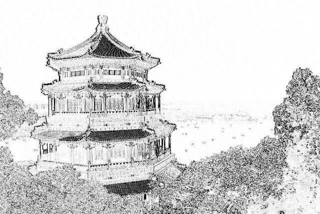

In [ ]:
import numpy as np
from PIL import Image

g = np.array(Image.open('pagode.png').convert('L')).astype(int)
h, b = g.shape
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from PIL import Image

g = np.array(Image.open('pagode.png').convert('L')).astype(int)
h, b = g.shape
kanten = np.clip(np.abs(g[:, 1:] - g[:, :-1]) * 3, 0, 255)
Image.fromarray((255 - kanten).astype(np.uint8))
```

</details>

#### Aufgabe 5.3

Kanten in **beide** Richtungen: Berechne die waagerechte Differenz `dx = g[:-1, 1:] - g[:-1, :-1]` und die senkrechte `dy = g[1:, :-1] - g[:-1, :-1]` (beide haben dieselbe Form)
und daraus `np.sqrt(dx² + dy²)`, mal 2 und auf 255 begrenzt. Zeige das Negativ an.

**Erwartete Ausgabe:**



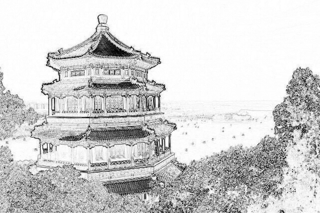

In [ ]:
import numpy as np
from PIL import Image

g = np.array(Image.open('pagode.png').convert('L')).astype(int)
h, b = g.shape
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from PIL import Image

g = np.array(Image.open('pagode.png').convert('L')).astype(int)
h, b = g.shape
dx = g[:-1, 1:] - g[:-1, :-1]
dy = g[1:, :-1] - g[:-1, :-1]
staerke = np.clip(np.sqrt(dx ** 2 + dy ** 2) * 2, 0, 255)
Image.fromarray((255 - staerke).astype(np.uint8))
```

</details>

#### Aufgabe 5.4

Schreibe eine Funktion `weichzeichnen(g, r)`, die den Mittelwert über ein (2r + 1) × (2r + 1)-Feld berechnet (für `r = 1` wie im Beispiel). Zeige die Ergebnisse für `r` = 2 und 6 an.

**Erwartete Ausgabe:**



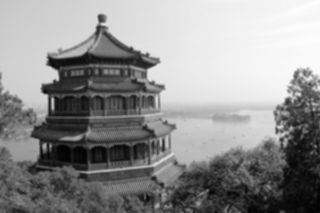

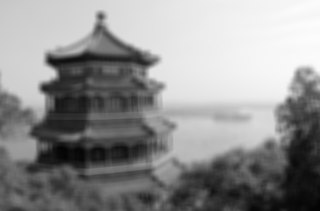

In [ ]:
import numpy as np
from PIL import Image

g = np.array(Image.open('pagode.png').convert('L')).astype(int)
h, b = g.shape
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from PIL import Image

g = np.array(Image.open('pagode.png').convert('L')).astype(int)
h, b = g.shape

def weichzeichnen(g, r):
    h, b = g.shape
    summe = np.zeros((h - 2 * r, b - 2 * r), dtype=int)
    for dy in range(-r, r + 1):
        for dx in range(-r, r + 1):
            summe += g[r + dy:h - r + dy, r + dx:b - r + dx]
    return (summe // (2 * r + 1) ** 2).astype(np.uint8)

for r in [2, 6]:
    display(Image.fromarray(weichzeichnen(g, r)))
```

</details>

#### Aufgabe 5.5

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
import numpy as np

g = np.array([[0, 0, 0, 90],
              [0, 0, 0, 90],
              [0, 0, 0, 90]])
print(np.abs(g[:, 1:] - g[:, :-1]))
print(g[0:3, 1:4].sum() // 9)

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

**Ausgabe:**

```
[[ 0  0 90]
 [ 0  0 90]
 [ 0  0 90]]
30
```

- Die Differenzen benachbarter Spalten sind 0, 0 und 90 (die Kante zwischen Spalte 2 und 3), in jeder Zeile gleich: drei Zeilen `[ 0  0 90]`.
- Das 3 × 3-Feld der Spalten 1 bis 3 enthält dreimal 90: `270 // 9 = 30`.

</details>

## 6. Unterschiede finden

#### `ImageChops.difference()`

`ImageChops.difference(a, b)` berechnet für jedes Pixel den Betrag der Differenz zweier gleich großer Bilder. Wo die Bilder gleich sind, ist das Ergebnis schwarz.
`differenz.getbbox()` gibt das kleinste Rechteck `(links, oben, rechts, unten)` zurück, das alle nicht-schwarzen Pixel enthält, oder `None`, wenn die Bilder gleich sind.

In [ ]:
from PIL import Image, ImageChops, ImageDraw

foto = Image.open('pagode.png').resize((320, 213))
veraendert = foto.copy()
ImageDraw.Draw(veraendert).circle((250, 60), 8, fill='red')
differenz = ImageChops.difference(foto, veraendert)
print(differenz.getbbox())
print(ImageChops.difference(foto, foto.copy()).getbbox())
differenz

#### Aufgabe 6.1

**Finde den Fehler**: In der Zelle wird in eine Kopie der Blüte an einer unbekannten Stelle ein kleines Rechteck gezeichnet. Finde es mit `ImageChops.difference()` und `getbbox()`,
gib die Lage aus und zeichne ein rotes Rechteck (Breite 3) um die gefundene Stelle in die Kopie.

**Erwartete Ausgabe:**

```
(185, 58, 192, 65)
```

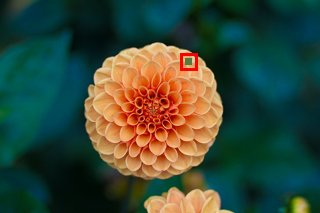

In [ ]:
from PIL import Image, ImageChops, ImageDraw
import random

foto = Image.open('bluete.png').resize((320, 213))
kopie = foto.copy()
random.seed(7)
x, y = random.randint(20, 290), random.randint(20, 180)
ImageDraw.Draw(kopie).rectangle((x, y, x + 6, y + 6), fill=(90, 120, 60))
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image, ImageChops, ImageDraw
import random

foto = Image.open('bluete.png').resize((320, 213))
kopie = foto.copy()
random.seed(7)
x, y = random.randint(20, 290), random.randint(20, 180)
ImageDraw.Draw(kopie).rectangle((x, y, x + 6, y + 6), fill=(90, 120, 60))
box = ImageChops.difference(foto, kopie).getbbox()
print(box)
links, oben, rechts, unten = box
ImageDraw.Draw(kopie).rectangle((links - 5, oben - 5, rechts + 5, unten + 5), outline='red', width=3)
kopie
```

</details>

#### Aufgabe 6.2

Wie stark verändert JPEG ein Bild? Speichere die verkleinerte Pagode als JPEG mit `quality=10` und `quality=90`, öffne beide und gib für beide die mittlere Differenz zum Original
aus (`ImageStat.Stat(differenz).mean`, ein Wert pro Kanal, eine Nachkommastelle). Zeige die Differenz bei Qualität 10 verstärkt an (`ImageEnhance.Brightness(...).enhance(8)`).

In [ ]:
from PIL import Image, ImageChops, ImageEnhance, ImageStat

foto = Image.open('pagode.png').resize((320, 213))
# your code

<details>
<summary>Beispiellösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image, ImageChops, ImageEnhance, ImageStat

foto = Image.open('pagode.png').resize((320, 213))
for qualitaet in [10, 90]:
    foto.save(f'test{qualitaet}.jpg', quality=qualitaet)
    differenz = ImageChops.difference(foto, Image.open(f'test{qualitaet}.jpg'))
    print(qualitaet, [round(m, 1) for m in ImageStat.Stat(differenz).mean])
ImageEnhance.Brightness(ImageChops.difference(foto, Image.open('test10.jpg'))).enhance(8)
```

</details>

## 7. Steganographie: eine versteckte Nachricht

#### Im untersten Bit verstecken

Ein Farbanteil ist eine Zahl von 0 bis 255, also 8 Bit. Ob das letzte Bit 0 oder 1 ist (ob die Zahl gerade oder ungerade ist), sieht niemand: 200 und 201 sind
für das Auge gleich. Dort kann man eine Nachricht verstecken (**Steganographie**):

1. Den Text mit `text.encode('utf-8')` in Bytes umwandeln und jedes Byte mit `format(byte, '08b')` in 8 Bits (Zeichen `'0'`/`'1'`).
2. Für jedes Bit den Rotanteil eines Pixels so ändern, dass `r % 2` dem Bit entspricht: `r - r % 2 + bit`.
3. Zum Lesen die Bits `r % 2` der Reihe nach einsammeln, je 8 mit `int(bits, 2)` in ein Byte umwandeln und mit `bytes(...).decode('utf-8')` wieder zu Text machen.

Damit man weiß, wo die Nachricht endet, hängt man ein Byte 0 an. Das Bild muss verlustfrei (PNG) gespeichert werden; JPEG würde die Bits zerstören.

In [ ]:
print('Hi'.encode('utf-8'), list('Hi'.encode('utf-8')))
print(format(72, '08b'), int('01001000', 2))
r = 201
print(r - r % 2 + 0, r - r % 2 + 1)

#### Aufgabe 7.1

Schreibe die Funktion `verstecken(foto, text)` (siehe Schritte oben): Sie verändert die Rotanteile der ersten Pixel (zeilenweise, `a[:, :, 0].flatten()`) und gibt ein neues Bild
zurück. Verstecke „Treffpunkt 15 Uhr“ in der Pagode, speichere das Ergebnis als `geheim.png` und gib aus, wie viele Bits versteckt wurden und wie viele Rotwerte sich geändert haben.

**Erwartete Ausgabe:**

```
144
68
```

In [ ]:
import numpy as np
from PIL import Image

foto = Image.open('pagode.png')
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from PIL import Image

foto = Image.open('pagode.png')

def verstecken(foto, text):
    a = np.array(foto)
    rot = a[:, :, 0].flatten()          # alle Rotanteile hintereinander
    bits = ''
    for byte in text.encode('utf-8') + bytes([0]):
        bits += format(byte, '08b')
    for i in range(len(bits)):
        rot[i] = rot[i] - rot[i] % 2 + int(bits[i])
    a[:, :, 0] = rot.reshape(a.shape[0], a.shape[1])
    return Image.fromarray(a)

geheim = verstecken(foto, 'Treffpunkt 15 Uhr')
geheim.save('geheim.png')
print(len('Treffpunkt 15 Uhr'.encode('utf-8')) * 8 + 8)
print((np.array(geheim)[:, :, 0] != np.array(foto)[:, :, 0]).sum())
```

</details>

#### Aufgabe 7.2

Schreibe die Funktion `lesen(foto)`, die die versteckte Nachricht wieder ausliest: Bits aus den Rotanteilen sammeln, je 8 zu einem Byte, beim Byte 0 aufhören.
Lies damit die Nachricht aus `geheim.png` (aus der vorigen Aufgabe) und zum Vergleich aus dem Original `pagode.png` und gib dort die gelesenen Bytes als Liste aus.
Im Original sind die ersten 8 Rotwerte zufällig alle gerade: Das erste Byte ist 0, die „Nachricht“ ist leer.

**Erwartete Ausgabe:**

```
Treffpunkt 15 Uhr
[]
```

In [ ]:
import numpy as np
from PIL import Image
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from PIL import Image

def lesen(foto):
    rot = np.array(foto)[:, :, 0].flatten()
    daten = []
    for start in range(0, len(rot) - 7, 8):
        bits = ''
        for wert in rot[start:start + 8]:
            bits += str(wert % 2)
        byte = int(bits, 2)
        if byte == 0:
            break
        daten.append(byte)
    return bytes(daten)

print(lesen(Image.open('geheim.png')).decode('utf-8'))
print(list(lesen(Image.open('pagode.png'))))
```

</details>

#### Aufgabe 7.3

Zeige, dass man den Unterschied nicht sieht: Zeige das Original und das Bild mit der Nachricht nebeneinander an (beide verkleinert) und gib den größten Unterschied eines Farbanteils aus
(`np.abs(... .astype(int) - ...).max()`).

**Erwartete Ausgabe:**

```
1
```

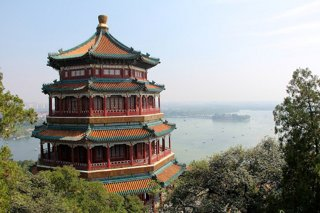

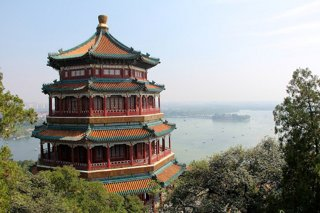

In [ ]:
import numpy as np
from PIL import Image

foto = Image.open('pagode.png')
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from PIL import Image

foto = Image.open('pagode.png')

def verstecken(foto, text):
    a = np.array(foto)
    rot = a[:, :, 0].flatten()          # alle Rotanteile hintereinander
    bits = ''
    for byte in text.encode('utf-8') + bytes([0]):
        bits += format(byte, '08b')
    for i in range(len(bits)):
        rot[i] = rot[i] - rot[i] % 2 + int(bits[i])
    a[:, :, 0] = rot.reshape(a.shape[0], a.shape[1])
    return Image.fromarray(a)

geheim = verstecken(foto, 'Treffpunkt 15 Uhr')
print(np.abs(np.array(geheim).astype(int) - np.array(foto).astype(int)).max())
display(foto.resize((320, 213)))
geheim.resize((320, 213))
```

</details>

#### Aufgabe 7.4

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
for r in [200, 201]:
    print(r - r % 2 + 1, r - r % 2 + 0, r % 2)

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

**Ausgabe:**

```
201 200 0
201 200 1
```

- Für 200 (gerade, letztes Bit 0): mit Bit 1 wird es `201`, mit Bit 0 bleibt es `200`; `200 % 2` ist `0`.
- Für 201 (ungerade): `201 - 1 = 200` ist die gerade Zahl darunter, mit Bit 1 also wieder `201`, mit Bit 0 `200`; `201 % 2` ist `1`.

</details>

## 8. Gemischte Übungen

#### Aufgabe 8.1

**Pop-Art**: Erzeuge aus der verkleinerten Blüte (160 × 107) vier Varianten mit vertauschten Kanälen (RGB, GBR, BRG und das Negativ) und setze sie mit `np.concatenate`
zu einem 2 × 2-Bild zusammen (zwei Zeilen nebeneinander mit `axis=1`, dann untereinander mit `axis=0`).

**Erwartete Ausgabe:**



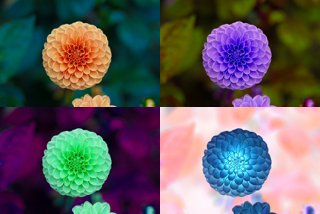

In [ ]:
import numpy as np
from PIL import Image

a = np.array(Image.open('bluete.png').resize((160, 107)))
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from PIL import Image

a = np.array(Image.open('bluete.png').resize((160, 107)))
oben = np.concatenate([a, a[:, :, [1, 2, 0]]], axis=1)
unten = np.concatenate([a[:, :, [2, 0, 1]], 255 - a], axis=1)
Image.fromarray(np.concatenate([oben, unten], axis=0))
```

</details>

#### Aufgabe 8.2

**Vignette**: Mache die Ränder der Pagode dunkler. Berechne für jedes Pixel den Abstand zur Bildmitte (mit `np.indices(a.shape[:2])` erhältst du Arrays mit allen `y`- und `x`-Werten),
teile durch den größten Abstand und multipliziere jeden Farbanteil mit `1 - 0.7 · (abstand / groesster)²`. Damit der Faktor auf alle drei Kanäle wirkt,
bekommt er mit `reshape(hoehe, breite, 1)` eine dritte Achse.

**Erwartete Ausgabe:**



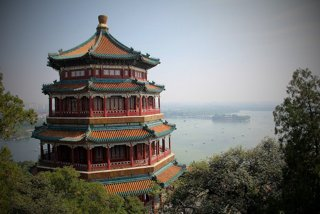

In [ ]:
import numpy as np
from PIL import Image

foto = Image.open('pagode.png')
a = np.array(foto)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from PIL import Image

foto = Image.open('pagode.png')
a = np.array(foto)
y, x = np.indices(a.shape[:2])
abstand = np.sqrt((x - a.shape[1] / 2) ** 2 + (y - a.shape[0] / 2) ** 2)
faktor = 1 - 0.7 * (abstand / abstand.max()) ** 2
ergebnis = (a * faktor.reshape(a.shape[0], a.shape[1], 1)).astype(np.uint8)
Image.fromarray(ergebnis)
```

</details>

#### Aufgabe 8.3

**ASCII-Kunst**: Verkleinere die Pagode in Graustufen auf 64 × 22 Pixel und gib für jedes Pixel ein Zeichen aus `' .:-=+*#%@'` aus (helle Pixel ein Leerzeichen, dunkle ein `@`):
Das Zeichen hat den Index `(255 - wert) * 9 // 255`.

**Erwartete Ausgabe:**

```
:...............................                                
...................:-..........                                 
...................-+:.........                                 
..................:+++:. .....                                  
...............:::--=+++-:.                                     
.........:------=++++++++**+-:..                                
.........-###########****#*##*=-.                               
:..........-##***#***+++**+=+-.                           .-::. 
-.......:-=+#####*+*****++**+--::                         -==--:
=-::....-*#####**************+==:.                       :--+*=-
++==-....-+##%####**#***#***+*+:...................... .:+=+++++
++++===-:=*#######*+*+++**++=---::::::::::::::::......:==+***+++
+++++++==*########+++++++++++------:::::..::::::::....:=+*****#*
+====-+########*#++++++++++++*+--=-:...................-==*#**#*
==----==**##***+***************+=-:::::::::::::.....:=--=+######
+=------**#%%%%%%##%%##%%%###*+++-:::::::::::--=---=+++=*#%%%#*#
++=====+%%%%%%%%%#########*+++------::----=++++++++*+++++#%%%###
+++++*##******+*#*++++++++++++=----=+++****#****++#****+*%%%%%##
**++++**++****++**++***+++++++++====**######***+*++***###%%%%%%%
+**+*+***+*****++++++=====+++++++++**#***#%#######**#**##%%%%%%%
+++=++**+++++****+**+++++*+*###+++####*++*########%%####%%%%%%%%
+*****+++*++++++*****+**+**+***+*+*******###****#%%%%%%%%%%%%%%%
```

In [ ]:
from PIL import Image

grau = Image.open('pagode.png').convert('L').resize((64, 22))
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image

grau = Image.open('pagode.png').convert('L').resize((64, 22))
zeichen = ' .:-=+*#%@'
for y in range(grau.height):
    zeile = ''
    for x in range(grau.width):
        zeile += zeichen[(255 - grau.getpixel((x, y))) * 9 // 255]
    print(zeile)
```

</details>

#### Aufgabe 8.4

Programmiere einen eigenen Effekt (z. B. Farben auf 4 Stufen pro Kanal reduzieren, ein Rauschen hinzufügen, ein Farbfilter wie bei einer Foto-App) und wende ihn auf ein Foto an.

In [ ]:
# your code

<details>
<summary>Beispiellösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from PIL import Image

a = np.array(Image.open('bluete.png'))
stufen = (a // 64) * 85
Image.fromarray(stufen.astype(np.uint8))
```

</details>